# Analyse de données walmart 

In [4]:
#importation des librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
#chargement de la base de données
Database = pd.read_csv("Walmart.csv")

In [6]:
#Affichage des types de données
Database.dtypes

transaction_id              int64
customer_id                 int64
product_id                  int64
product_name               object
category                   object
quantity_sold               int64
unit_price                float64
transaction_date           object
store_id                    int64
store_location             object
inventory_level             int64
reorder_point               int64
reorder_quantity            int64
supplier_id                 int64
supplier_lead_time          int64
customer_age                int64
customer_gender            object
customer_income           float64
customer_loyalty_level     object
payment_method             object
promotion_applied            bool
promotion_type             object
weather_conditions         object
holiday_indicator            bool
weekday                    object
stockout_indicator           bool
forecasted_demand           int64
actual_demand               int64
dtype: object

In [7]:
#informations sur la base de données
Database.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_id          5000 non-null   int64  
 1   customer_id             5000 non-null   int64  
 2   product_id              5000 non-null   int64  
 3   product_name            5000 non-null   object 
 4   category                5000 non-null   object 
 5   quantity_sold           5000 non-null   int64  
 6   unit_price              5000 non-null   float64
 7   transaction_date        5000 non-null   object 
 8   store_id                5000 non-null   int64  
 9   store_location          5000 non-null   object 
 10  inventory_level         5000 non-null   int64  
 11  reorder_point           5000 non-null   int64  
 12  reorder_quantity        5000 non-null   int64  
 13  supplier_id             5000 non-null   int64  
 14  supplier_lead_time      5000 non-null   

In [8]:
Database.shape

(5000, 28)

In [9]:
#Affichage des 20 premières ligen du dataset
Database.head(20)

,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,store_location,...,customer_loyalty_level,payment_method,promotion_applied,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,"Miami, FL",...,Silver,Credit Card,True,NaN,Stormy,False,Friday,True,172,179
1,2,1409,135,TV,Electronics,4,1912.04,7/28/2024 12:45,5,"Dallas, TX",...,Gold,Cash,True,Percentage Discount,Rainy,False,Monday,True,109,484
2,3,5506,391,Fridge,Electronics,4,1377.75,6/10/2024 4:55,1,"Los Angeles, CA",...,Platinum,Cash,False,NaN,Sunny,False,Tuesday,True,289,416
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,"Miami, FL",...,Silver,Cash,True,Percentage Discount,Sunny,True,Sunday,False,174,446
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,"Chicago, IL",...,Bronze,Digital Wallet,False,NaN,Sunny,False,Thursday,True,287,469
5,6,3286,630,Camera,Electronics,4,1465.38,7/6/2024 7:24,1,"New York, NY",...,Bronze,Credit Card,True,NaN,Sunny,True,Saturday,False,294,265
6,7,2679,238,Laptop,Appliances,3,1904.70,3/17/2024 22:33,3,"Dallas, TX",...,Platinum,Cash,False,BOGO,Sunny,False,Sunday,True,178,257
7,8,9935,409,Tablet,Electronics,4,875.16,7/22/2024 13:57,16,"Los Angeles, CA",...,Silver,Debit Card,False,Percentage Discount,Rainy,True,Thursday,True,165,264
8,9,2424,106,Camera,Electronics,4,1627.48,3/30/2024 4:10,12,"New York, NY",...,Platinum,Credit Card,False,NaN,Sunny,True,Saturday,True,476,428
9,10,7912,407,Laptop,Appliances,5,666.27,6/17/2024 16:59,10,"Chicago, IL",...,Bronze,Digital Wallet,True,NaN,Sunny,True,Monday,True,395,400


# 1. Analyse exploratoire des données

In [11]:
#Nombre des observations null
Database['promotion_type'].isnull()

0        True
1       False
2        True
3       False
4        True
        ...  
4995     True
4996     True
4997     True
4998     True
4999    False
Name: promotion_type, Length: 5000, dtype: bool

In [ ]:
# valeur manquantes
Database.isnull().sum()

transaction_id               0
customer_id                  0
product_id                   0
product_name                 0
category                     0
quantity_sold                0
unit_price                   0
transaction_date             0
store_id                     0
store_location               0
inventory_level              0
reorder_point                0
reorder_quantity             0
supplier_id                  0
supplier_lead_time           0
customer_age                 0
customer_gender              0
customer_income              0
customer_loyalty_level       0
payment_method               0
promotion_applied            0
promotion_type            3407
weather_conditions           0
holiday_indicator            0
weekday                      0
stockout_indicator           0
forecasted_demand            0
actual_demand                0
dtype: int64

In [ ]:
Database['promotion_type']

0                       NaN
1       Percentage Discount
2                       NaN
3       Percentage Discount
4                       NaN
               ...         
4995                    NaN
4996                    NaN
4997                    NaN
4998                    NaN
4999                   BOGO
Name: promotion_type, Length: 5000, dtype: object

In [20]:
# remplacement des valeurs manquantes par la plus fréquente
Database['promotion_type'].fillna(Database['promotion_type'].mode()[0], inplace=True)


In [21]:
Database['promotion_type']

0                      BOGO
1       Percentage Discount
2                      BOGO
3       Percentage Discount
4                      BOGO
               ...         
4995                   BOGO
4996                   BOGO
4997                   BOGO
4998                   BOGO
4999                   BOGO
Name: promotion_type, Length: 5000, dtype: object

### Analyse descriptive

In [22]:
#analyse descriptive
Database.describe()

,transaction_id,customer_id,product_id,quantity_sold,unit_price,store_id,inventory_level,reorder_point,reorder_quantity,supplier_id,supplier_lead_time,customer_age,customer_income,forecasted_demand,actual_demand
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,2500.500000,5542.497200,551.233400,2.982800,1023.467294,10.525000,253.121800,99.788000,200.517000,300.12560,5.523000,44.124000,70041.627846,297.134000,299.08840
std,1443.520003,2582.126997,258.826606,1.419474,559.614242,5.786888,142.885456,29.132387,58.257381,116.39486,2.863549,15.329358,29053.371736,115.568806,121.68078
min,1.000000,1001.000000,100.000000,1.000000,50.100000,1.000000,0.000000,50.000000,100.000000,100.00000,1.000000,18.000000,20005.340000,100.000000,90.00000
25%,1250.750000,3279.000000,322.000000,2.000000,537.775000,5.000000,130.000000,75.000000,150.750000,199.00000,3.000000,31.000000,44865.417500,195.000000,194.00000
50%,2500.500000,5558.000000,559.000000,3.000000,1029.175000,11.000000,253.000000,100.000000,200.500000,299.00000,6.000000,44.000000,70188.290000,297.500000,299.00000
75%,3750.250000,7767.250000,776.000000,4.000000,1506.307500,16.000000,377.250000,125.000000,251.000000,405.00000,8.000000,58.000000,95395.872500,395.000000,404.00000
max,5000.000000,9998.000000,999.000000,5.000000,1999.850000,20.000000,500.000000,150.000000,300.000000,500.00000,10.000000,70.000000,119999.780000,500.000000,510.00000


In [23]:
# Creer une colone ville et une autre departement
df = pd.DataFrame(Database)
# Séparer la colonne "location" en deux colonnes : ville et département
df[['Town', 'departement']] = df['store_location'].str.split(',', expand=True)
df = df.drop('store_location', axis = 1)
df


,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,inventory_level,...,promotion_applied,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand,Town,departement
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,246,...,True,BOGO,Stormy,False,Friday,True,172,179,Miami,FL
1,2,1409,135,TV,Electronics,4,1912.04,7/28/2024 12:45,5,43,...,True,Percentage Discount,Rainy,False,Monday,True,109,484,Dallas,TX
2,3,5506,391,Fridge,Electronics,4,1377.75,6/10/2024 4:55,1,411,...,False,BOGO,Sunny,False,Tuesday,True,289,416,Los Angeles,CA
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,452,...,True,Percentage Discount,Sunny,True,Sunday,False,174,446,Miami,FL
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,412,...,False,BOGO,Sunny,False,Thursday,True,287,469,Chicago,IL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,6898,852,Headphones,Appliances,1,682.15,7/8/2024 6:13,17,75,...,False,BOGO,Sunny,False,Wednesday,True,257,294,New York,NY
4996,4997,8412,886,Laptop,Appliances,3,1418.09,2/7/2024 11:30,16,207,...,True,BOGO,Sunny,True,Sunday,True,388,397,Los Angeles,CA
4997,4998,8331,934,Fridge,Electronics,5,398.66,8/20/2024 0:38,16,182,...,True,BOGO,Cloudy,False,Thursday,True,314,204,New York,NY
4998,4999,7505,439,Laptop,Appliances,3,1000.95,8/26/2024 11:05,16,75,...,True,BOGO,Stormy,False,Tuesday,False,488,144,Miami,FL


In [28]:
#Utiliser GROUPBY afin de calculer le produit le prodiuit le plus vendu
Database_qtite_total = df.groupby("product_name")["quantity_sold"].sum().reset_index()
Database_qtite_total

,product_name,quantity_sold
0,Camera,1873
1,Fridge,1967
2,Headphones,1816
3,Laptop,1685
4,Smartphone,1876
5,TV,1926
6,Tablet,1964
7,Washing Machine,1807


In [33]:
# Trouver le produit le plus vendu
produit_plus_vendu = Database_qtite_total.loc[Database_qtite_total["quantity_sold"].idxmax()]
print("Le produit le plus vendu est :", produit_plus_vendu["product_name"], 
      "avec", produit_plus_vendu["quantity_sold"], "ventes.")

Le produit le plus vendu est : Fridge avec 1967 ventes.


In [37]:
#Utiliser GROUPBY afin de calculer le produit le prodiuit le plus vendu en fonction des villes 
Database_qtite_total_town = df.groupby(["product_name", "Town"])["quantity_sold"].sum().reset_index()
Database_qtite_total_town

,product_name,Town,quantity_sold
0,Camera,Chicago,413
1,Camera,Dallas,335
2,Camera,Los Angeles,387
3,Camera,Miami,360
4,Camera,New York,378
5,Fridge,Chicago,385
6,Fridge,Dallas,388
7,Fridge,Los Angeles,398
8,Fridge,Miami,354
9,Fridge,New York,442


In [38]:
produit_plus_vendu_par_ville = Database_qtite_total_town.loc[
    Database_qtite_total_town.groupby("Town")["quantity_sold"].idxmax()
]

print(produit_plus_vendu_par_ville)


   product_name         Town  quantity_sold
25           TV      Chicago            490
31       Tablet       Dallas            420
22   Smartphone  Los Angeles            417
33       Tablet        Miami            386
9        Fridge     New York            442


In [41]:
# Matrice de corrélation entre toutes les colonnes numériques
correlation_matrix = df.select_dtypes(include=["number"]).corr()
correlation_matrix

,transaction_id,customer_id,product_id,quantity_sold,unit_price,store_id,inventory_level,reorder_point,reorder_quantity,supplier_id,supplier_lead_time,customer_age,customer_income,forecasted_demand,actual_demand
transaction_id,1.000000,0.003323,0.004999,0.000563,0.004316,0.014608,0.019780,0.012894,0.014109,0.015366,0.006474,-0.003550,0.013125,-0.002619,-0.009382
customer_id,0.003323,1.000000,-0.022306,0.003460,-0.000040,0.011599,0.016079,-0.006148,-0.010205,0.014085,-0.007920,0.012919,-0.001235,0.005033,-0.000363
product_id,0.004999,-0.022306,1.000000,0.001037,-0.013503,-0.006449,0.006741,-0.022253,0.000516,0.015200,0.010436,0.016281,-0.002330,0.001525,-0.029530
quantity_sold,0.000563,0.003460,0.001037,1.000000,-0.000098,0.000345,-0.018018,-0.000185,-0.011978,-0.006406,-0.005562,-0.004186,0.005052,0.035487,-0.033150
unit_price,0.004316,-0.000040,-0.013503,-0.000098,1.000000,-0.009060,-0.016513,0.021947,0.007345,0.001105,-0.009418,0.006862,0.006361,0.005038,0.022234
store_id,0.014608,0.011599,-0.006449,0.000345,-0.009060,1.000000,0.017001,-0.012239,0.001335,-0.012232,-0.008461,0.009132,-0.020547,-0.011269,-0.015559
inventory_level,0.019780,0.016079,0.006741,-0.018018,-0.016513,0.017001,1.000000,-0.009400,-0.028048,0.000899,0.002828,0.007036,0.004355,0.002030,0.003255
reorder_point,0.012894,-0.006148,-0.022253,-0.000185,0.021947,-0.012239,-0.009400,1.000000,-0.011879,0.008601,0.009991,0.007793,-0.001567,0.015332,-0.020646
reorder_quantity,0.014109,-0.010205,0.000516,-0.011978,0.007345,0.001335,-0.028048,-0.011879,1.000000,0.000641,-0.000972,-0.005515,-0.002966,-0.000494,-0.003781
supplier_id,0.015366,0.014085,0.015200,-0.006406,0.001105,-0.012232,0.000899,0.008601,0.000641,1.000000,-0.048529,-0.005193,-0.007394,-0.026947,-0.009362


In [11]:
Database.head()

,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,store_location,...,customer_loyalty_level,payment_method,promotion_applied,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,"Miami, FL",...,Silver,Credit Card,True,NaN,Stormy,False,Friday,True,172,179
1,2,1409,135,TV,Electronics,4,1912.04,7/28/2024 12:45,5,"Dallas, TX",...,Gold,Cash,True,Percentage Discount,Rainy,False,Monday,True,109,484
2,3,5506,391,Fridge,Electronics,4,1377.75,6/10/2024 4:55,1,"Los Angeles, CA",...,Platinum,Cash,False,NaN,Sunny,False,Tuesday,True,289,416
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,"Miami, FL",...,Silver,Cash,True,Percentage Discount,Sunny,True,Sunday,False,174,446
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,"Chicago, IL",...,Bronze,Digital Wallet,False,NaN,Sunny,False,Thursday,True,287,469


# 2. Calcul des KPI

### Gestions des Ventes

In [26]:
#calcul du chiffre d'affaire
df['chiffre affaire'] = df['quantity_sold'] * df['unit_price'] 
df['chiffre affaire']

0        565.38
1       7648.16
2       5511.00
3        911.55
4       1497.84
         ...   
4995     682.15
4996    4254.27
4997    1993.30
4998    3002.85
4999     710.03
Name: chiffre affaire, Length: 5000, dtype: float64

In [27]:
df.head()

,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,inventory_level,...,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand,Town,departement,chiffre affaire
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,246,...,BOGO,Stormy,False,Friday,True,172,179,Miami,FL,565.38
1,2,1409,135,TV,Electronics,4,1912.04,7/28/2024 12:45,5,43,...,Percentage Discount,Rainy,False,Monday,True,109,484,Dallas,TX,7648.16
2,3,5506,391,Fridge,Electronics,4,1377.75,6/10/2024 4:55,1,411,...,BOGO,Sunny,False,Tuesday,True,289,416,Los Angeles,CA,5511.00
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,452,...,Percentage Discount,Sunny,True,Sunday,False,174,446,Miami,FL,911.55
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,412,...,BOGO,Sunny,False,Thursday,True,287,469,Chicago,IL,1497.84


C:\Users\HP\AppData\Local\Temp\ipykernel_13888\3854993166.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=chiffre_affaire_par_produit.index, y=chiffre_affaire_par_produit.values, palette="viridis")


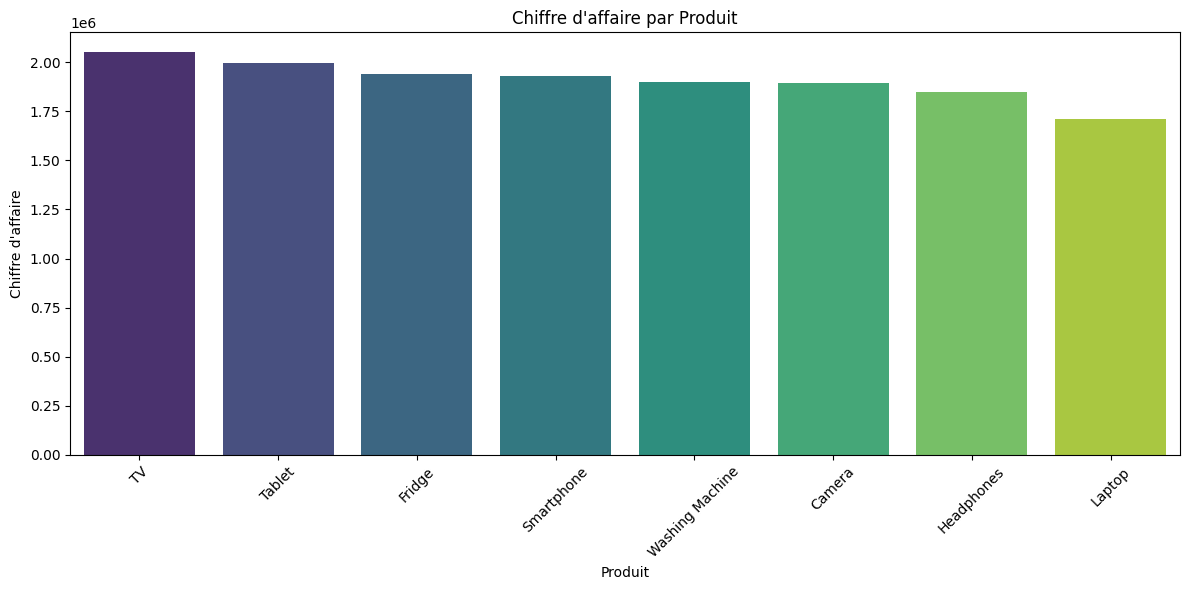

In [28]:
# Visualisation du chiffre d'affaire par produit
plt.figure(figsize=(12, 6))
chiffre_affaire_par_produit = df.groupby('product_name')['chiffre affaire'].sum().sort_values(ascending=False)
sns.barplot(x=chiffre_affaire_par_produit.index, y=chiffre_affaire_par_produit.values, palette="viridis")
plt.xticks(rotation=45)
plt.xlabel('Produit')
plt.ylabel('Chiffre d\'affaire')
plt.title('Chiffre d\'affaire par Produit')
plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_13888\4074611540.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ventes_par_category.index, y=ventes_par_category.values, palette="viridis")


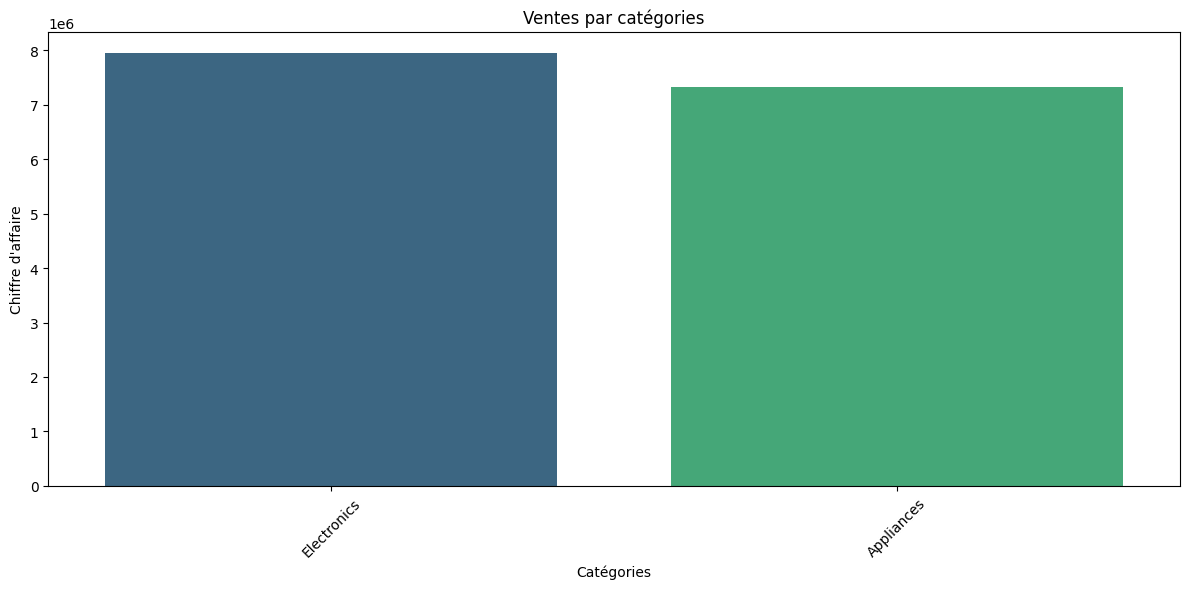

In [ ]:
#visualisation des ventes par catégorie
plt.figure(figsize=(12, 6))
ventes_par_category = df.groupby('category')['chiffre affaire'].sum().sort_values(ascending=False)
sns.barplot(x=ventes_par_category.index, y=ventes_par_category.values, palette="viridis")
plt.xticks(rotation=45)
plt.xlabel('Catégories')
plt.ylabel('Chiffre d\'affaire')
plt.title('Ventes par catégories')
plt.tight_layout()
plt.show()


- Promotion qui génère le plus de ventes

C:\Users\HP\AppData\Local\Temp\ipykernel_13888\3915008028.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Ventes_par_promotion.index, y=Ventes_par_promotion.values, palette="viridis")


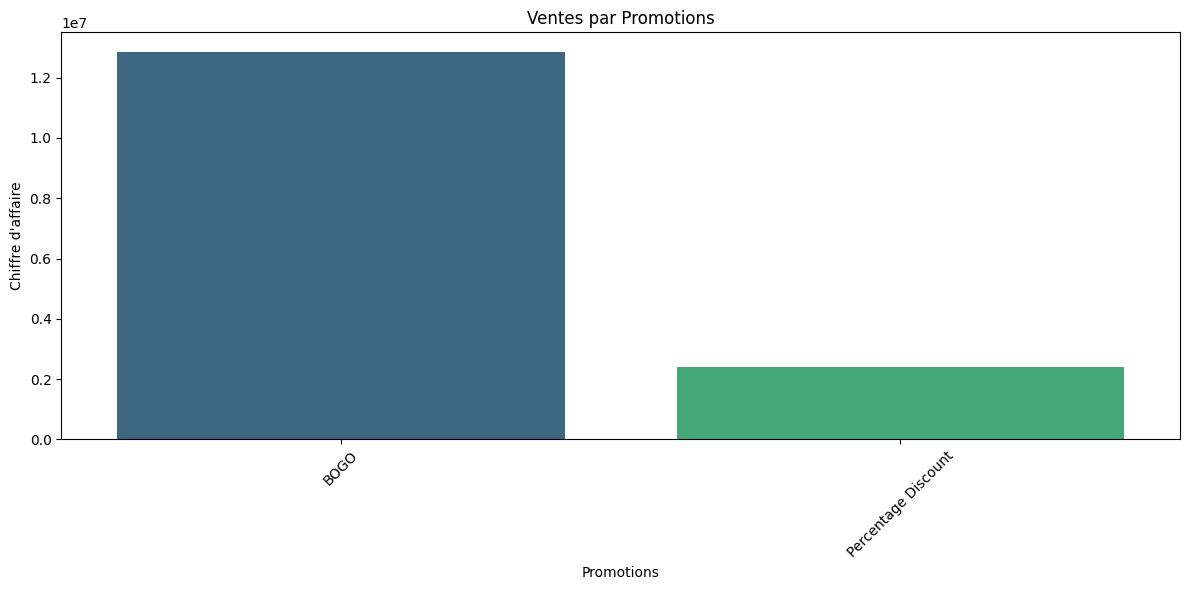

In [36]:
# chiffre d'affaire par promotion 
#visualisation des ventes par produit
plt.figure(figsize=(12, 6))
Ventes_par_promotion = df.groupby('promotion_type')['chiffre affaire'].sum().sort_values(ascending=False)
sns.barplot(x=Ventes_par_promotion.index, y=Ventes_par_promotion.values, palette="viridis")
plt.xticks(rotation=45)
plt.xlabel('Promotions')
plt.ylabel('Chiffre d\'affaire')
plt.title('Ventes par Promotions')
plt.tight_layout()
plt.show()

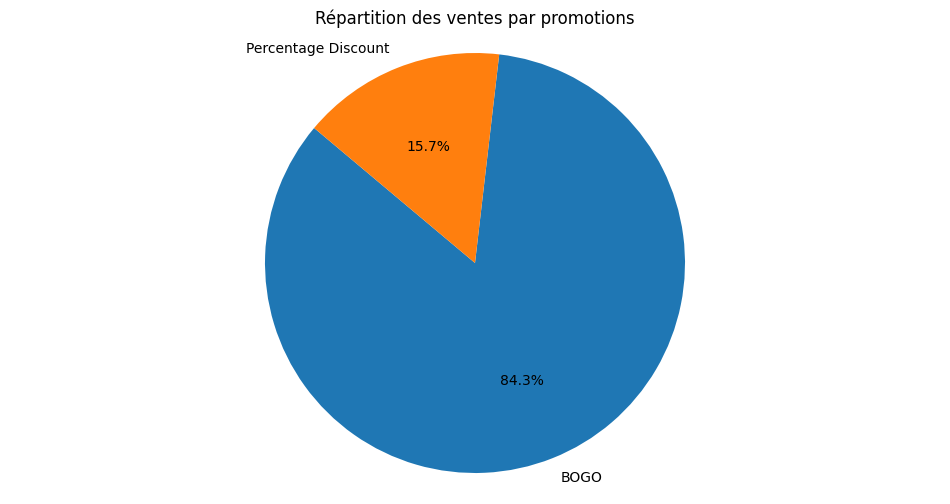

In [46]:
#graphique en pie
plt.figure(figsize=(12, 6))
plt.pie(Ventes_par_promotion, labels=Ventes_par_promotion.index, autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.title('Répartition des ventes par promotions')
plt.show()

- la ville qui génère plus de ventes


In [38]:
#la ville qui génère plus de chiffre d'affaire
Ventes_par_pays = df.groupby('Town')['chiffre affaire'].sum().sort_values(ascending=False)
Ventes_par_pays

Town
Los Angeles    3276299.63
Chicago        3156726.82
New York       2964077.24
Miami          2962567.02
Dallas         2903930.74
Name: chiffre affaire, dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_13888\3112466751.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Ventes_par_pays.index, y=Ventes_par_pays.values, palette="husl")


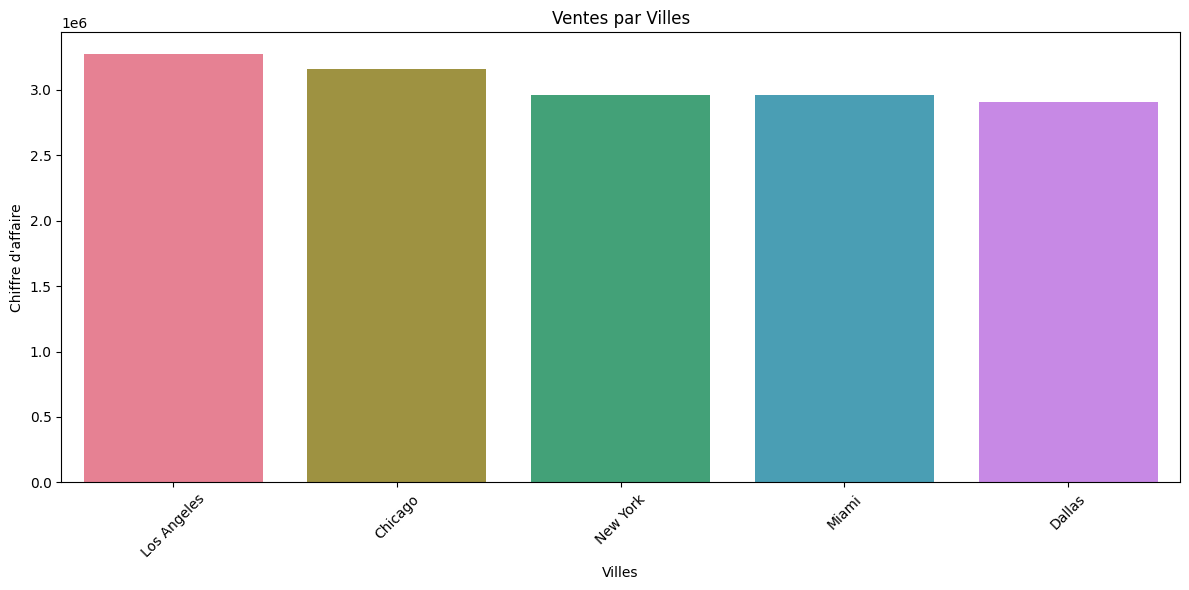

In [39]:
plt.figure(figsize=(12, 6))
sns.barplot(x=Ventes_par_pays.index, y=Ventes_par_pays.values, palette="husl")
plt.xticks(rotation=45)
plt.xlabel('Villes')
plt.ylabel('Chiffre d\'affaire')
plt.title('Ventes par Villes')
plt.tight_layout()
plt.show()

-  le jour de la semaine ou les ventes sont élevé

In [43]:
# ventes par week
Ventes_par_semaine = df.groupby('weekday')['chiffre affaire'].sum().sort_index(ascending=False)
Ventes_par_semaine

weekday
Wednesday    2095912.06
Tuesday      2126494.17
Thursday     2436640.72
Sunday       1938101.13
Saturday     2222858.28
Monday       2433795.67
Friday       2009799.42
Name: chiffre affaire, dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_13888\1411539934.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Ventes_par_semaine.index, y=Ventes_par_semaine.values, palette="husl")


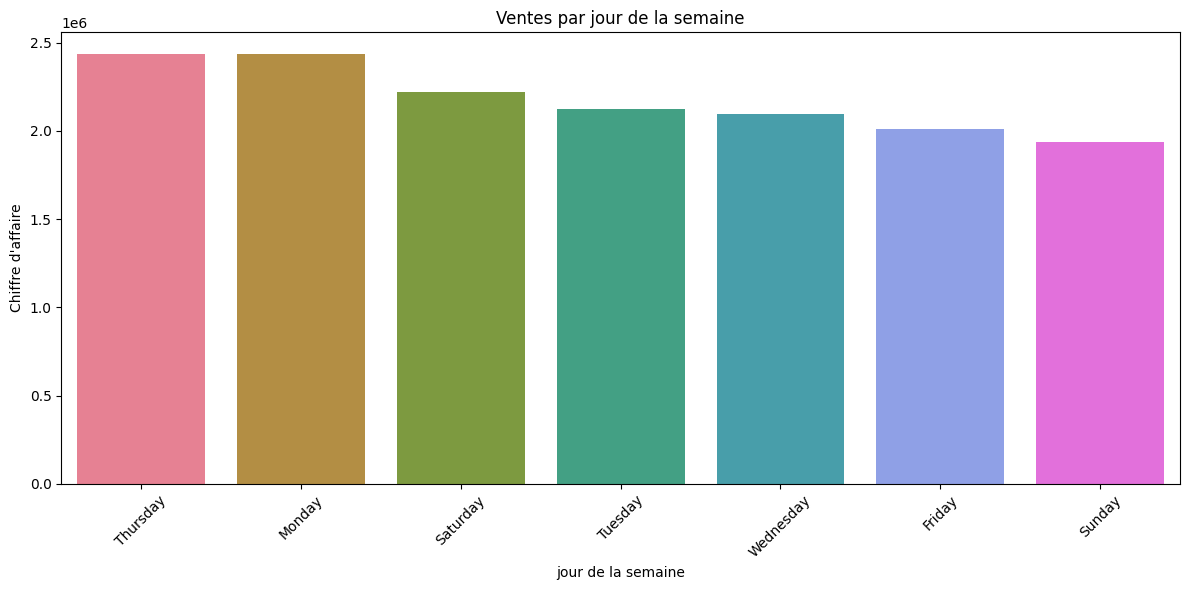

In [41]:
plt.figure(figsize=(12, 6))
sns.barplot(x=Ventes_par_semaine.index, y=Ventes_par_semaine.values, palette="husl")
plt.xticks(rotation=45)
plt.xlabel('jour de la semaine')
plt.ylabel('Chiffre d\'affaire')
plt.title('Ventes par jour de la semaine')
plt.tight_layout()
plt.show()

- le temps ou les Ventes s'éffectuent le plus 

In [44]:
# ventes par méteo
Ventes_par_meteo = df.groupby('weather_conditions')['chiffre affaire'].sum().sort_values(ascending=False)
Ventes_par_meteo

weather_conditions
Sunny     3979603.69
Cloudy    3878416.82
Stormy    3843358.52
Rainy     3562222.42
Name: chiffre affaire, dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_13888\1809387144.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Ventes_par_meteo.index, y=Ventes_par_meteo.values, palette="pastel")


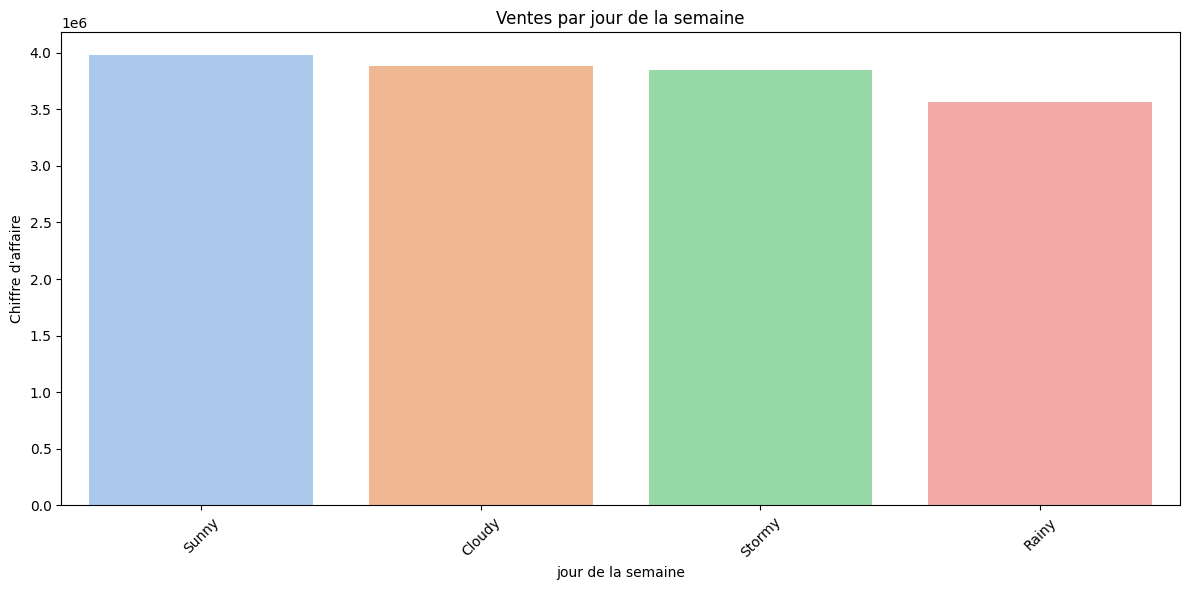

In [45]:
# graphique des ventes par meteo
plt.figure(figsize=(12, 6))
sns.barplot(x=Ventes_par_meteo.index, y=Ventes_par_meteo.values, palette="pastel")
plt.xticks(rotation=45)
plt.xlabel('jour de la semaine')
plt.ylabel('Chiffre d\'affaire')
plt.title('Ventes par jour de la semaine')
plt.tight_layout()
plt.show()

# 2.  Gestions des Stock